### **Maestría en Inteligencia Artificial Aplicada**

###**Curso: Inteligencia Artificial y Aprendizaje Automático**

**Tecnológico de Monterrey**

Prof Luis Eduardo Falcón Morales

### **Actividad de la Semana: Problema de Clasificación con Datos Desbalanceados : Oil-Spill**

* **Nombre:** Darío Martín Romero Cruz

* **Matrícula:** A01841015

# **Introducción**

* La actividad se basa en los datos conocidos como "oil-spill" (derrame de petróleo).

* En la web puedes encontrar varias referencias a este mismo problema, pero en donde el archivo de datos no es exactamente igual. Por ello y para asegurar que el conjunto de datos con el que estaremos trabajando es el mismo para todos, dicho archivo lo encontrarás en Canvas.

* El archivo con los datos de esta actividad lo encuentras en Canvas con el nombre "oil-spill.csv".

* En la siguiente liga se encuentra el artículo original relacionado a dicha base de datos:

https://webdocs.cs.ualberta.ca/~holte/Publications/oilspill.pdf

* De dicho artículo sabemos que los datos incluyen 50 columnas y 937 registros. Las primeras 49 columnas son métricas obtenidas de imágenes satelitales del océano, en algunas de las cuales se tiene petróleo que fue derramado por alguna fuente desconocida. En el artículo se describe a detalle la manera en que se obtuvieron dichas columnas. Para la presente actividad es suficiente con saber que dichos valores numéricos son información valiosa que nos permiten entender lo qu hay en la imagen, en particular, el ayudar a distinguir si hay o no derramamiento de combustible en dicha imagen.

* La última columna llamada "target" puede tomar el valor de 1 (hay derrame en ese pedazo de la imagen) o 0 (no hay derrame en ese pedazo de la imagen).

* Así, por el momento es suficiente con que consideres que cada una de las primeras 49 columnas son variables de tipo numérico continua y la última es de valor binario, en este problema de clasificación.

* En un curso posterior de visión computacional dentro de la maestría podrás estudiar técnicas para extraer dicha información numérica de las imágenes, en caso de que este tema sea de tu interés.

* Para fines de esta actividad usaremos la librería llamada "imbalanced-learn", usada comunmente en problemas de clases desbalanceadas. En particular, usaremos el siguiente método que nos proporciona un reporte con los valores de varias métricas utilizadas comunmente en problemas de clases desbalanceadas:

https://imbalanced-learn.org/stable/references/generated/imblearn.metrics.classification_report_imbalanced.html

In [1]:
# Incluye a continuación todas librerías que consideres necesarias:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, RepeatedStratifiedKFold, StratifiedKFold, cross_val_score, cross_validate, cross_val_predict, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer

from sklearn.preprocessing import PowerTransformer, StandardScaler
from sklearn.impute import SimpleImputer

from sklearn.metrics import make_scorer, accuracy_score, confusion_matrix, RocCurveDisplay, PrecisionRecallDisplay
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from imblearn.metrics import geometric_mean_score, classification_report_imbalanced

**NOTAS:**

* **Para fines de esta actividad, pre-procesaremos los datos de manera genérica para poder concentrarnos en los temas relacionados al curso.**

* **Siempre podrás regresar en el futuro y trabajar de mejor manera el pre-procesamiento de los datos.**

In [2]:
# Cargamos los datos del archivo de la actividad:
path ='oil_spill.csv'
df = pd.read_csv(path)

# Eliminamos las siguientes columnas:
#   - f_1 contiene información de secciones (batches) de las imágenes que no requerimos para esta actividad.
#   - f_23 tiene un solo valor constante.
df.drop("f_1", axis=1, inplace=True)
df.drop("f_23", axis=1, inplace=True)

# Despleguemos los primeros valores:
print('Dimensión del DataFrame',df.shape)
df.head(4).T


Dimensión del DataFrame (937, 48)


,0,1,2,3
f_2,2558.00,22325.00,115.00,1201.00
f_3,1506.09,79.11,1449.85,1562.53
f_4,456.63,841.03,608.43,295.65
f_5,90.00,180.00,88.00,66.00
f_6,6395000.00,55812500.00,287500.00,3002500.00
f_7,40.88,51.11,40.42,42.40
f_8,7.89,1.21,7.34,7.97
f_9,29780.00,61900.00,3340.00,18030.00
f_10,0.19,0.02,0.18,0.19
f_11,214.70,901.70,86.10,166.50


In [3]:
# Particionamos los datos de entrada (X) y de salida (y):
X,y = df.iloc[:,:-1], df.iloc[:,-1]

# Utilizamos las semillas indicadas para la reproducibilidad de los resultados de la actividad:
Xtv, Xtest, ytv, ytest = train_test_split(X, y, test_size=0.12, stratify=y, shuffle=True, random_state=1)
Xtrain, Xval, ytrain, yval = train_test_split(Xtv, ytv, test_size=0.2, shuffle=True, random_state=7)


# Veamos que tenemos un problema de clases bastante desbalanceadas.
# Para ello mostremos la distribución de los conjuntos de entrenamiento, validación y prueba.
# En realidad, solo deberíamos mostrar los valores del conjunto de entrenamiento
# para evitar el problema del filtrado de información (data leakage). Sin embargo,
# con fines meramente euducativos, mostramos también la distribución de los conjuntos
# de validación (val) y de prueba (test), para darnos una idea de la complejidad del
# problema y del reto que tenemos para entrenar un buen modelo de clasificación.
# Es decir, tenemos una cantidad muy pequeña de datos de la clase positiva
# en el conjunto de validación y en el de prueba y aún así, deberemos
# hacer el esfuerzo para diseñar un buen modelo que distinga estos pocos datos.

print('\nPartición de los conjuntos de Entrenamiento, Validación y Prueba:')
print('+'*70)
tmp = 100 * (ytrain.sum() / len(ytrain))
print('Train:')
print('Conteo_clase_positiva= %d (%.2f%%)' % (ytrain.sum(), tmp))
print('Conteo_clase_negativa= %d (%.2f%%)' % ((len(ytrain)-ytrain.sum()), 100-tmp))

print('\nValidation:')
tmp = 100 * (yval.sum() / len(yval))
print('Conteo_clase_positiva= %d (%.2f%%)' % (yval.sum(), tmp))
print('Conteo_clase_negativa= %d (%.2f%%)' % ((len(yval)-yval.sum()), 100-tmp))

print('\nTest:')
tmp = 100 * (ytest.sum() / len(ytest))
print('Conteo_clase_positiva= %d (%.2f%%)' % (ytest.sum(), tmp))
print('Conteo_clase_negativa= %d (%.2f%%)' % ((len(ytest)-ytest.sum()), 100-tmp))


Partición de los conjuntos de Entrenamiento, Validación y Prueba:
++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++
Train:
Conteo_clase_positiva= 28 (4.25%)
Conteo_clase_negativa= 631 (95.75%)

Validation:
Conteo_clase_positiva= 8 (4.85%)
Conteo_clase_negativa= 157 (95.15%)

Test:
Conteo_clase_positiva= 5 (4.42%)
Conteo_clase_negativa= 108 (95.58%)


# **Ejercicio-1**

### **Consideremos en primer instancia que los errores de falsos poitivos y falsos negativos son igualmente costosos. Y ya que tenemos un problema bastante desbalanceado, usaremos la media geométrica como métrica principal para buscar el mejor modelo. A partir de esta información, responde las siguientes preguntas:**

* ### **a) En el contexto de este problema del derrame de petróleo, ¿cómo justificas el no utilizar la métrica de la exactitud (accuracy), y sí utlizar la métrica G_mean?**

* ### **b) En el contexto del problema ¿qué significa un Falso Positivo y cuáles podrían ser algunas de sus implicaciones al cometer uno de estos errores?**

* ### **c) En el contexto del problema ¿qué significa un Falso Negativo y cuáles podrían ser algunas de sus implicaciones al cometer uno de estos errores?**





Respuestas Ejercicio-1:

### +++++++++++ Inicia sección para agregar texto ++++++++++++++++

* 1a) Sabemos que en un problema desbalanceado tenemos un gran número de individuos de la clase negativa (95.7% en este caso) y pocos de la clase positiva (4.3%). En este contexto, incluso el modelo ingenuo ya nos daría una exactitud del 95.7% pero sería inútil para la guardia costera. Por esta razón se debe considerar una métrica adicional.
El G-mean es una métrica que aplica raíz cuadrada al producto de las proporciones de aciertos en cada clase. Esto último obliga a que el modelo sea bueno acertando ambas para obtener valores cercanos a 1.

* 1b) Un falso positivo significa que nuestro modelo clasifica la imagen con derrame pero realmente no lo había. Esto podría llevar a maniobras de inspección en la zona que probablemente no sean necesarias. Requiriendo personal y costos en la operación. Muchas falsas alarmas podrían ser problemáticas ya que esto conlleva a poca confianza en el modelo, además, el personal que las está atendiendo deja de estar disponible para otras situaciones.

* 1c) Un falso negativo significa que nuestro modelo clasifica la imagen sin derrame cuando sí lo había. Este es el escenario más grave porque puede conllevar daños ecológicos enormes al extenderse la mancha del derrame si no es atendida con rapidez.

### +++++++++++ Termina sección para agregar texto ++++++++++++++

* **Incluyamos a continuación una breve descripción numérica y gráfica del conjunto de entrenamiento. Es lo mínimo en cuanto a pre-procesamiento que haremos. Más adelante puedes regresar y realizar un mayor análisis.**

* **En dado caso, puedes incluir más celdas con análisis adicionales, si así lo deseas.**

In [4]:
Xtrain.describe().T

,count,mean,std,min,25%,50%,75%,max
f_2,659.0,350.377845,1.911459e+03,10.00,19.000,63.00,134.000,28526.00
f_3,659.0,692.040516,6.013521e+02,1.92,83.905,646.26,1229.325,1789.13
f_4,659.0,853.822398,5.259526e+02,1.00,435.500,719.81,1238.040,2724.57
f_5,659.0,85.613050,4.564260e+01,0.00,54.000,74.00,120.500,180.00
f_6,659.0,831366.966616,4.158159e+06,71718.00,125000.000,185000.00,337500.000,71315000.00
f_7,659.0,43.517132,1.287405e+01,21.24,33.760,40.35,53.090,82.64
f_8,659.0,9.244294,3.590490e+00,1.21,6.935,8.33,11.045,23.47
f_9,659.0,4094.624431,8.960913e+03,704.00,1332.000,2100.00,3445.000,160740.00
f_10,659.0,0.221730,8.687786e-02,0.02,0.170,0.21,0.260,0.67
f_11,659.0,110.794537,6.187135e+01,41.00,84.400,100.10,116.300,901.70


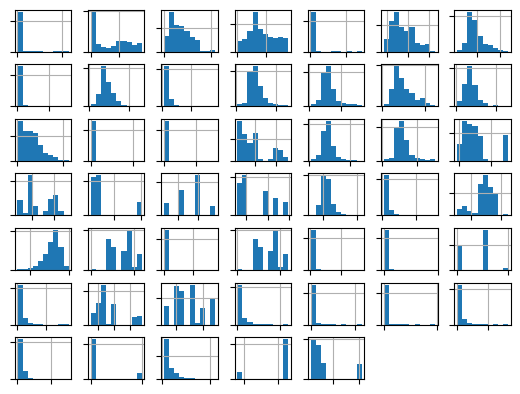

In [5]:
# Histogramas:
ax = Xtrain.hist()
# Quitemos toda la información del gráfico para visualizarlos de manera sencilla:
for axis in ax.flatten():
  axis.set_title('')
  axis.set_xticklabels([])
  axis.set_yticklabels([])
plt.show()



In [6]:
Xtrain.info()

<class 'pandas.core.frame.DataFrame'>
Index: 659 entries, 433 to 625
Data columns (total 47 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   f_2     659 non-null    int64  
 1   f_3     659 non-null    float64
 2   f_4     659 non-null    float64
 3   f_5     659 non-null    int64  
 4   f_6     659 non-null    float64
 5   f_7     659 non-null    float64
 6   f_8     659 non-null    float64
 7   f_9     659 non-null    float64
 8   f_10    659 non-null    float64
 9   f_11    659 non-null    float64
 10  f_12    659 non-null    float64
 11  f_13    659 non-null    float64
 12  f_14    659 non-null    float64
 13  f_15    659 non-null    float64
 14  f_16    659 non-null    float64
 15  f_17    659 non-null    float64
 16  f_18    659 non-null    float64
 17  f_19    659 non-null    float64
 18  f_20    659 non-null    float64
 19  f_21    659 non-null    float64
 20  f_22    659 non-null    float64
 21  f_24    659 non-null    float64
 22  f_25 

**En resumen:**

* De lo anterior observamos que:
  * Todos los valores ya son numéricos, positivos, negativos o cero.
  * No hay datos perdidios.
  * La diferencia de escala entre todos los factores es muy diversa y la distribución de las variables también es muy variada.

* **Como una primera aproximación transformaremos todos los factores con la Yeo-Johnson para corregir un poco el sesgo de las distribuciones que suele afectar en general a los modelos como la regresión logística y luego los escalaremos para ayudar a que todos los factores estén en iguales condiciones de mostrar su importancia.**

# **Ejercicio-2**

### **En relación a la transformación Yeo-Johnson, investiga:**

* ### **a) ¿En qué consiste dicha transformación?**

* ### **b) ¿Cuál es su diferencia con la transformación Box-Cox?**


Respuestas Ejercicio-2:

### +++++++++++ Inicia sección para agregar texto ++++++++++++++++

* 2a) Es una transformación para reducir el sesgo y estabilizar la varianza, así como reducir el efecto de los outliers. Es una extensión de la de Box-Cox, útil tanto para variables positivas como negativas. Toma la siguiente fórmula:

$$
X_{transf} = 
\begin{cases} 
\frac{(X + 1)^\lambda - 1}{\lambda} & \text{si } \lambda \neq 0 \text{ y } X \geq 0 \\ 
\log(X + 1) & \text{si } \lambda = 0 \text{ y } X \geq 0 \\ 
-\frac{(-X + 1)^{2-\lambda} - 1}{2 - \lambda} & \text{si } \lambda \neq 2 \text{ y } X < 0 \\ 
-\log(-X + 1) & \text{si } \lambda = 2 \text{ y } X < 0 
\end{cases}
$$

Aquí, el parámetro $\lambda$ corresponde al Estimador de Máxima Verosimilitud para cada variable, de modo que la variable transformada se parezca lo más posible a una normal.

* 2b) La fórmula de Box-Cox igual es una transformada para reducir el sesgo pero solo aplica a variables estrictamente positivas. Su fórmula es:

$$
X_{transf} = 
\begin{cases} 
\frac{X^\lambda - 1}{\lambda} & \text{si } \lambda \neq 0 \\ 
\log(X) & \text{si } \lambda = 0 
\end{cases}
$$



### +++++++++++ Termina sección para agregar texto ++++++++++++++

In [7]:
# Transformaciones numéricas evitando el filtrado de información:

from sklearn.preprocessing import MinMaxScaler

numericas_pipeline = Pipeline(steps = [('impMediana', SimpleImputer(strategy='mean')),
                                       ('yeo-johnson', PowerTransformer(method='yeo-johnson')),
                                       ('std_transformer', StandardScaler()),
                                       ])

numericas_pipeline_nombres = Xtrain.columns

columnasTransformer = ColumnTransformer(transformers = [('num', numericas_pipeline, numericas_pipeline_nombres)],
                                        remainder='passthrough')


# **Ejercicio-3**

### **En este ejercicio deberás obtener el valor de umbral del modelo base (baseline) con el conjunto de entrenamiento, que nos ayude a determinar si un modelo está subentrenado.**

* ### **a) Encuentra la estrategia (strategy) del DummyClassifier más adecuada. Además, selecciona el número de divisiones (n_splits) de RepeatedStratifiedKFold que consideres sea el más adecuado para particionar en los conjuntos de entrenamiento y validación al aplicar validación cruzada con el modelo DummyClassifier. Prueba varios valores y observa el resultado de la media y desviación estándar antes de hacer tu mejor selección. Responde a continuación cómo llegaste a decidirte por valor que seleccionaste.**

* ### **b) Con base a tu mejor decisión para "strategy" y "n_splits", ¿cuál es el valor que se usará para determinar si un modelo está subentrenado, al usar la métrica G_mean?**

* ### **c) Si utilizáramos la métrica de la exactitud (accuracy) en este problema del derrame del petróleo, ¿cuál sería el valor de umbral del modelo base a superar? Incluye además la matriz de confusión de este modelo ingenuo con la métrica de la exactitud.**

Respuestas Ejercicio-3:

### +++++++++++ Inicia sección para agregar texto ++++++++++++++++


* 3a) Se selecciona la estrategia `uniform` porque es la que arroja valores más altos del G-mean. Esto tiene sentido, ya que las estrategias `most_frequent`, `prior` y `constant` siempre dan un mismo valor, por lo que la tasa de acierto de una de las dos clases se vuelve cero, haciendo cero el G-mean. `stratified` es un poco mejor porque no anula el G-mean, pero de todas maneras se encuentra bajo al predecir muchos resultados negativos. `uniform` es el mejor ya que arroja 0 o 1 con probabilidad del 50%, así que el G-mean también es cercano a ese 50%. Por su parte, se elige $n_{splits} = 3$ porque es la que obtiene la menor desviación estándar (0.067), y con eso, la estimación más estable. Además, elegir un valor más grande dejaría muy pocos casos de derrame por fold (e.g. 2 o 3 casos con $n_{splits} = 10$).

* 3b) El valor de referencia para determinar si es un modelo subentrenado será: *G-mean = 0.551* (promedio de los valores generados en la validación cruzada).

* 3c) Para la *exactitud*, el modelo base es el modelo ingenuo, el cual siempre predecirá 0 (no derrame). La *exactitud* de dicho modelo es $631/659 = 0.957$, y su matriz de confusión es:

<center>

| | Predicción 0 | Predicción 1 |
|---|:---:|:---:|
| **Real 0** | 631 | 0 |
| **Real 1** | 28 | 0 |

</center>

### +++++++++++ Termina sección para agregar texto ++++++++++++++

NOTA: Recuerda revisar la documentación correspondiente de sklearn para la selección adecuada de los argumentos:

* DummyClassifier:

https://scikit-learn.org/stable/modules/generated/sklearn.dummy.DummyClassifier.html

* RepeatedStratifiedKFold:

https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.RepeatedStratifiedKFold.html

In [8]:
# Definamos una variable con la métrica G-mean a utilizar en los modelos:

mi_metrica = make_scorer(geometric_mean_score)


In [9]:
# Utilicemos la función DummyClassifier de sklearn con la métrica G-mean para
# obtener el desempeño del modelo base (baseline).

# Usa esta celda para probar diferentes valores de "strategy" y "n_splits".
# Con base a los resultados observados selecciona tus mejores opciones y
# responde a las preguntas de los incisos anteriores del Ejercicio-3.


# ----------------- Incluye a continuación tus mejores opciones -----------

estrategias = ['most_frequent', 'prior', 'stratified', 'uniform', 'constant']
for est in estrategias:
    for k in [3, 5, 7, 10]:
        cvx = RepeatedStratifiedKFold(n_splits=k, n_repeats=3, random_state=7)
        extra = {'constant': 1} if est == 'constant' else {}
        pipe = Pipeline([('ct', columnasTransformer),
                         ('Dummy', DummyClassifier(strategy=est, random_state=7, **extra))])
        s = cross_val_score(pipe, Xtrain, ytrain, scoring=mi_metrica, cv=cvx, n_jobs=-1)
        print(f'{est:14s} k={k:2d}  G-mean={s.mean():.3f} ({s.std():.3f})')
    print('')

mi_estrategia = 'uniform'

mi_nsplits = 3

# ----------------- Fin para realizar ajustes -----------------------------


# No modifiques las semillas.
cv = RepeatedStratifiedKFold(n_splits=mi_nsplits, n_repeats=3, random_state=7)  # Validación Cruzada Estratificada.
modeloD = DummyClassifier(strategy=mi_estrategia, random_state=7)
pipelineD = Pipeline(steps=[('ct',columnasTransformer),('Dummy',modeloD)])
scores = cross_val_score(pipelineD, Xtrain, ytrain, scoring=mi_metrica, cv=cv, n_jobs=-1)  # Cuidamos el filtrado de información.

print('Veamos los desempeños obtenidos con la DummyClassifier y la métrica G-mean.')
print('Imprimimos los resultados de todas las secciones (folds) generadas con Validación-Cruzada:')
print('+'*90)
print(scores)


print('\nObtenemos el valor promedio y desviación estandar (std) de dichos resultados:')
print('+'*80)
print('Promedio de los desempeños con la G-mean[Media Geométrica]=%.3f, std=(%.3f)' % (np.mean(scores), np.std(scores)))


most_frequent  k= 3  G-mean=0.000 (0.000)
most_frequent  k= 5  G-mean=0.000 (0.000)
most_frequent  k= 7  G-mean=0.000 (0.000)
most_frequent  k=10  G-mean=0.000 (0.000)

prior          k= 3  G-mean=0.000 (0.000)
prior          k= 5  G-mean=0.000 (0.000)
prior          k= 7  G-mean=0.000 (0.000)
prior          k=10  G-mean=0.000 (0.000)

stratified     k= 3  G-mean=0.071 (0.133)
stratified     k= 5  G-mean=0.054 (0.138)
stratified     k= 7  G-mean=0.000 (0.000)
stratified     k=10  G-mean=0.000 (0.000)

uniform        k= 3  G-mean=0.551 (0.067)
uniform        k= 5  G-mean=0.508 (0.137)
uniform        k= 7  G-mean=0.489 (0.081)
uniform        k=10  G-mean=0.493 (0.163)

constant       k= 3  G-mean=0.000 (0.000)
constant       k= 5  G-mean=0.000 (0.000)
constant       k= 7  G-mean=0.000 (0.000)
constant       k=10  G-mean=0.000 (0.000)

Veamos los desempeños obtenidos con la DummyClassifier y la métrica G-mean.
Imprimimos los resultados de todas las secciones (folds) generadas con Validaci

# **Ejercicio-4**

* ### **Ya que tenemos las referencias de los modelos base (baseline) o ingenuo (naive) para las métricas de exactitud (accuracy) y G-mean. Ejecuta a continuación la siguiente celda. Observa que estaremos ejecutando los modelos con el mínimo de ajuste de los valores predeterminados de los hiperparámetros. Esto con el objetivo de tener un punto de partida sobre qué tan alejados estamos de obtener buenos modelos. Sirve también como ejemplo para mostrar cómo se  desempeñan los modelos cuando se ejecutan con sus valores predeterminados, que en muchas ocasiones son los resultados que muestran algunos LLM (modelos grandes de lenguaje). Esto nos muestra que no porque no tengamos errores de ejecución o compilación, no significa que ya alcanzamos el objetivo buscado.**

* ### **Observa que estamos usando los conjuntos Xtv y ytv para entrenar los modelos ya que estamos utilizando validación cruzada y además, mostramos al inicio que tenemos muy pocos datos de la clase positiva minoritaria en el conjunto de validación.**

In [10]:
# Omite los warnings generados por el parametro penalty en LogisticRegression, los cuales fueron deprecados en la versión 1.8
import warnings
warnings.filterwarnings('ignore', category=FutureWarning, message=".*'penalty' was deprecated.*")
warnings.filterwarnings('ignore', category=UserWarning, message="Inconsistent values: penalty=")

# Omite el warning de joblib/loky en Windows
import os
os.environ['LOKY_MAX_CPU_COUNT'] = '4'

Resultados de Validación:
LR
Exactitud: >> 0.947 (0.014)
G-mean: >> 0.654 (0.119)

LASSO
Exactitud: >> 0.960 (0.009)
G-mean: >> 0.501 (0.158)

RIDGE
Exactitud: >> 0.959 (0.008)
G-mean: >> 0.541 (0.113)

EN
Exactitud: >> 0.960 (0.007)
G-mean: >> 0.540 (0.109)

kNN
Exactitud: >> 0.956 (0.006)
G-mean: >> 0.174 (0.187)



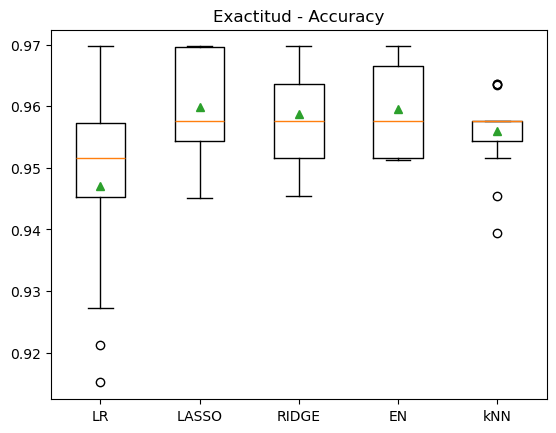

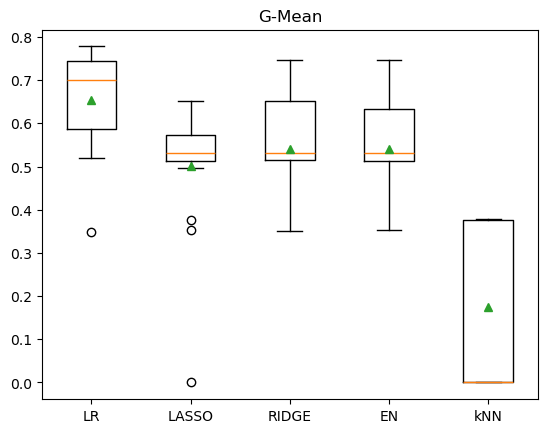

In [11]:
# Código-1:

# Ejecuta esta celda sin modificaciones.

# Estamos ejecutando los modelos con el mínimo de ajustes para usar sus valores predetermiandos
# y mostrando los desempeños con las métricas de exactitud (accuracy) y G-mean.

# Definimos primeramente los modelos a entrenar y evaluar:

def mis_modelos1():
  modelos, nombres = list(), list()

  modelos.append(LogisticRegression(penalty=None, # Este valor del argumento define el modelo sin regularización.
                                    max_iter=2000,
                                    random_state=1))
  nombres.append('LR')


  modelos.append(LogisticRegression(penalty='l1',  # modelo Lasso o de métrica L1.
                                    solver='liblinear',
                                    max_iter=2000,
                                    random_state=1))
  nombres.append('LASSO')


  modelos.append(LogisticRegression(penalty='l2',   # modelo Ridge o de métrica L2.
                                    max_iter=2000,
                                    random_state=1))
  nombres.append('RIDGE')

  modelos.append(LogisticRegression(penalty='elasticnet',  # modelo Elastic-Net o de métrica L1-L2.
                                    l1_ratio=0.5,
                                    solver='saga',
                                    max_iter=5000,
                                    random_state=1))
  nombres.append('EN')

  modelos.append(KNeighborsClassifier(n_neighbors=5))
  nombres.append('kNN')

  return modelos, nombres

# +++++++++++++++++++++++++++++++++++++++++++++++++++++++++


modelos, nombres = mis_modelos1()
resultados1, resultados2 = list(), list()
print('Resultados de Validación:')

for i in range(len(modelos)):

  pipeline = Pipeline(steps=[('ct',columnasTransformer),('m',modelos[i])])
  cv1 = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=7)
  scores = cross_validate(pipeline,
                          Xtv,
                          np.ravel(ytv),
                          scoring={'exactitud':'accuracy', 'm_geo':mi_metrica},
                          cv=cv1)

  resultados1.append(scores['test_exactitud'])
  resultados2.append(scores['test_m_geo'])

  print(nombres[i])
  print('Exactitud: >> %.3f (%.3f)' % (np.nanmean(scores['test_exactitud']), np.nanstd(scores['test_exactitud'])))
  print('G-mean: >> %.3f (%.3f)' % (np.nanmean(scores['test_m_geo']), np.nanstd(scores['test_m_geo'])))
  print()

plt.boxplot(resultados1, tick_labels=nombres,  showmeans=True)
plt.title("Exactitud - Accuracy")
plt.show()

plt.boxplot(resultados2, tick_labels=nombres,  showmeans=True)
plt.title("G-Mean")
plt.show()




### **Habiendo ejecutado la celda anterior sin ajustar hiperparámetros, responde lo siguiente:**

### **4a) ¿Cuáles modelos están subentrenados con respecto a la métrica de la exactitud (accuracy)?**

### **4b) ¿Cuáles modelos están subentrenados con respecto a la métrica de la media geométrica (G-mean)?**


### +++++++++++ Inicia sección para agregar texto ++++++++++++++++


* 4a) Los modelos subentrenados con respecto a la métrica de exactitud fueron: `LR` con 0.947 y `kNN` con 0.956.

* 4b) Los modelos subentrenados con respecto a la métrica de G-mean fueron: `kNN` con 0.174, `LASSO` con 0.501, `EN` con 0.540 y `RIDGE` con 0.541.


### +++++++++++ Termina sección para agregar texto ++++++++++++++

# **Ejercicio-5**

* ### **Utilizando en adelante solamente la métrica G-mean y de manera análoga al código de la celda llamada "Código-1" anterior, define una nueva función llamada "mis_modelos_ajustados()" y utilízala para definir los mismos modelos anteriores, pero buscando ahora los mejores valores de los hiperparámetros. Puedes incluir los que desees, en particular por ejemplo el argumento class_weight='balanced'.**

* ### **La salida no deberá mostrar errores o advertencias (warnings).**

* ### **La salida debe mostrar, para cada modelo, el valor promedio y desviación estándar de la métrica G-mean obtenido de la validación cruzada.**

* ### **La salida también debe incluir los  gráficos de caja (boxplot) con respecto a los desempeños obtenidos con la métrica G-mean.**


* ### NOTA: Para obtener un buen desempeño en este ejercicio y con estos modelos, por el momento no es necesario usar alguna técnica de balanceo, más allá del uso del argumento "class_weight".

In [12]:
# 5) Búsqueda de los mejores hiperparámetros con GridSearchCV,
# usando la misma validación cruzada que Código-1 y la métrica G-mean.

cv5 = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=7)

busquedas = {
  'LR':    (LogisticRegression(C=1e10, max_iter=20000, random_state=1),   # C muy grande = sin regularización
            {'m__class_weight': [None, 'balanced', {0: 1, 1: 5}, {0: 1, 1: 10}]}),
  'LASSO': (LogisticRegression(l1_ratio=1, solver='liblinear', max_iter=10000, random_state=1),
            {'m__C': [0.005, 0.01, 0.02, 0.05, 0.1, 0.5, 1, 10], 'm__class_weight': [None, 'balanced']}),
  'RIDGE': (LogisticRegression(l1_ratio=0, max_iter=10000, random_state=1),
            {'m__C': [0.001, 0.005, 0.01, 0.02, 0.05, 0.1, 0.5, 1, 10], 'm__class_weight': [None, 'balanced']}),
  'EN':    (LogisticRegression(solver='saga', max_iter=20000, random_state=1),
            {'m__C': [0.005, 0.01, 0.02, 0.05, 0.1, 0.5, 1], 'm__l1_ratio': [0.2, 0.5, 0.8],
             'm__class_weight': ['balanced']}),
  'kNN':   (KNeighborsClassifier(),
            {'m__n_neighbors': [1, 2, 3, 5, 7], 'm__weights': ['uniform', 'distance'], 'm__p': [1, 2]}),
}

print('Mejores hiperparámetros encontrados con GridSearchCV (métrica G-mean):')
print('+'*80)
for nombre, (modelo, grid) in busquedas.items():
    gs = GridSearchCV(Pipeline([('ct', columnasTransformer), ('m', modelo)]),
                      grid, scoring=mi_metrica, cv=cv5, n_jobs=-1)
    gs.fit(Xtv, np.ravel(ytv))
    std_mejor = gs.cv_results_['std_test_score'][gs.best_index_]
    print(f'{nombre:6s} G-mean = {gs.best_score_:.3f} ({std_mejor:.3f})  ->  {gs.best_params_}')

Mejores hiperparámetros encontrados con GridSearchCV (métrica G-mean):
++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++
LR     G-mean = 0.754 (0.121)  ->  {'m__class_weight': 'balanced'}
LASSO  G-mean = 0.849 (0.042)  ->  {'m__C': 0.05, 'm__class_weight': 'balanced'}
RIDGE  G-mean = 0.817 (0.106)  ->  {'m__C': 0.01, 'm__class_weight': 'balanced'}
EN     G-mean = 0.844 (0.042)  ->  {'m__C': 0.02, 'm__class_weight': 'balanced', 'm__l1_ratio': 0.8}
kNN    G-mean = 0.497 (0.101)  ->  {'m__n_neighbors': 1, 'm__p': 1, 'm__weights': 'uniform'}


Resultados de los modelos ajustados con la métrica G-mean
++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++
LR
G-mean: >> 0.754 (0.121)

LASSO
G-mean: >> 0.849 (0.042)

RIDGE
G-mean: >> 0.817 (0.106)

EN
G-mean: >> 0.844 (0.042)

kNN
G-mean: >> 0.497 (0.101)



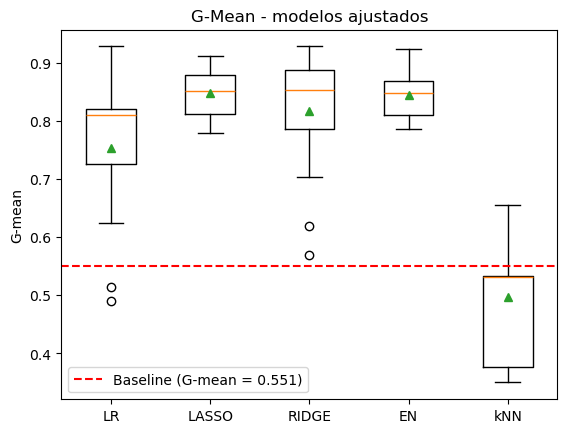

In [13]:
# 5)

print('Resultados de los modelos ajustados con la métrica G-mean')
print('+'*80)

# ++++++++++ Inicia sección para agregar tu código ++++++++++++++++++++++++
# NOTA: puedes agregar todas las celdas que consideres adecuado.
# Hiperparámetros obtenidos con GridSearchCV (celda anterior)

def mis_modelos_ajustados():
  modelos, nombres = list(), list()
  modelos.append(LogisticRegression(C=1e10, class_weight='balanced', max_iter=20000, random_state=1))
  nombres.append('LR')
  modelos.append(LogisticRegression(l1_ratio=1, solver='liblinear', C=0.05, class_weight='balanced',
                                    max_iter=10000, random_state=1))
  nombres.append('LASSO')
  modelos.append(LogisticRegression(l1_ratio=0, C=0.01, class_weight='balanced', max_iter=10000, random_state=1))
  nombres.append('RIDGE')
  modelos.append(LogisticRegression(l1_ratio=0.8, solver='saga', C=0.02, class_weight='balanced',
                                    max_iter=20000, random_state=1))
  nombres.append('EN')
  modelos.append(KNeighborsClassifier(n_neighbors=1, p=1))
  nombres.append('kNN')
  return modelos, nombres

modelos, nombres = mis_modelos_ajustados()
cv5 = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=7)
resultados = []
for nombre, modelo in zip(nombres, modelos):
    pipeline = Pipeline(steps=[('ct', columnasTransformer), ('m', modelo)])
    scores = cross_val_score(pipeline, Xtv, np.ravel(ytv), scoring=mi_metrica, cv=cv5, n_jobs=-1)
    resultados.append(scores)
    print('%s\nG-mean: >> %.3f (%.3f)\n' % (nombre, np.nanmean(scores), np.nanstd(scores)))

plt.boxplot(resultados, tick_labels=nombres, showmeans=True)
plt.axhline(y=0.551, color='red', linestyle='--', linewidth=1.5,
            label=f'Baseline (G-mean = {0.551:.3f})')
plt.title('G-Mean - modelos ajustados')
plt.ylabel('G-mean')
plt.legend(loc='lower left')
plt.show()

# ++++++++++ Termina sección para agregar tu código ++++++++++++++++++++++++


# **Ejercicio-6**

### **a) Selecciona el que consideres sea el mejor modelo encontrado, busca la mejor configuración de hiperparámetros y utilízalo para encontrar su matriz de confusión. Llamarlo "mejor_modelo". Sigue utilizando los mismos conjuntos de entrenamiento y validación. Llamar "ytrain_hat" y "yval_hat" a las predicciones de los conjuntos de entrenamiento y validación, respectivamente, obtenidas con el mejor modelo. Verifica ahora que tampoco quede sobreentrenado, considerando que la diferencia entre entrenamiento y validación no sea mayor al $3\%$. Utilizar random_state=1 en el modelo seleccionado.**

### **b) Observa que estamos también mostrando los valores de la exactitud de este mejor modelo. ¿Cómo justificas que el valor de la exactitud es menor que el obtenido anteriormente? Compara con la salida de la celda llamada "Código-1".**

###  **c) Con el mejor modelo y el conjunto de validación, obtener el gráfico de la curva-ROC, donde se incluya el valor del área bajo la curva AUC del mejor modelo y también el AUC del modelo que predice siempre la clase positiva (chance level). Ver documentación.**

###  **d) Con el mejor modelo y el conjunto de validación, obtener el gráfico de la curva-PR, donde se incluya el valor del área bajo la curva AUC del mejor modelo y también el AUC del modelo que siempre predice la clase positiva (chance level). Ver documentación.**

### **e) Con base a los resultados de los gráficos ROC y PR incluye tus conclusiones en el contexto del problema.**




In [14]:
# Respuesta Ejercicio-6a:

# **+++++++++++ Inicia sección para agregar código ++++++++++++++++**

# NOTA: puedes agregar todas las celdas que consideres adecuado.


# Búsqueda del mejor modelo: entrenamos con Xtrain y evaluamos con Xval,
# exigiendo que la brecha de G-mean entre entrenamiento y validación sea <= 3%.
candidatos = {
    'LASSO': dict(l1_ratio=1, solver='liblinear'),
    'RIDGE': dict(l1_ratio=0),
    'EN':    dict(l1_ratio=0.8, solver='saga'),
}
valores_C = [0.005, 0.01, 0.02, 0.03, 0.05, 0.1, 0.5, 1, 5, 10]

filas = []
for nombre, params in candidatos.items():
    for C in valores_C:
        modelo = Pipeline([('ct', columnasTransformer),
                           ('m', LogisticRegression(C=C, class_weight='balanced', max_iter=20000,
                                                    random_state=1, **params))])
        modelo.fit(Xtrain, np.ravel(ytrain))
        g_tr = geometric_mean_score(np.ravel(ytrain), modelo.predict(Xtrain))
        g_va = geometric_mean_score(np.ravel(yval), modelo.predict(Xval))
        filas.append({'modelo': nombre, 'C': C, 'G_train': g_tr, 'G_val': g_va,
                      'brecha': abs(g_tr - g_va)})

busqueda = pd.DataFrame(filas)
busqueda['brecha<=3%'] = np.where(busqueda['brecha'] <= 0.03, 'x', '')
validos = busqueda[busqueda['brecha'] <= 0.03]
mejor = validos.sort_values(['G_val', 'brecha'], ascending=[False, True]).iloc[0]

print(busqueda.round(4).to_string(index=False))
print('\nMejor configuración (brecha <= 3%):')
print(mejor.round(4).to_string())
print()

# Construimos el mejor modelo con la configuración encontrada:
mejor_modelo = Pipeline([('ct', columnasTransformer),
                         ('m', LogisticRegression(C=mejor['C'], class_weight='balanced', max_iter=20000,
                                                  random_state=1, **candidatos[mejor['modelo']]))])
mejor_modelo.fit(Xtrain, np.ravel(ytrain))

ytrain_hat = mejor_modelo.predict(Xtrain)

yval_hat = mejor_modelo.predict(Xval)



# **+++++++++++ Termina sección para agregar código ++++++++++++++**

print('G-mean del mejor modelo-Train: %.4f' % geometric_mean_score(np.ravel(ytrain), ytrain_hat))
print('G-mean del mejor modelo-Val: %.4f' % geometric_mean_score(np.ravel(yval), yval_hat))

print('\nExactitud del mejor modelo-Train: %.4f' % accuracy_score(np.ravel(ytrain), ytrain_hat))
print('Exactitud del mejor modelo-Val: %.4f' % accuracy_score(np.ravel(yval), yval_hat))

print("\nMatriz de Confusión con Validación:\n", confusion_matrix(np.ravel(yval), yval_hat))

print("\nMatriz de Confusión en porcentajes y con Validación:\n", confusion_matrix(np.ravel(yval), yval_hat, normalize='all'))

modelo      C  G_train  G_val  brecha brecha<=3%
 LASSO  0.005   0.7053 0.7655  0.0602           
 LASSO  0.010   0.7053 0.7655  0.0602           
 LASSO  0.020   0.7805 0.8294  0.0489           
 LASSO  0.030   0.8164 0.8923  0.0759           
 LASSO  0.050   0.8378 0.9135  0.0757           
 LASSO  0.100   0.8611 0.9341  0.0731           
 LASSO  0.500   0.9118 0.9375  0.0258          x
 LASSO  1.000   0.9267 0.9443  0.0176          x
 LASSO  5.000   0.9596 0.9544  0.0052          x
 LASSO 10.000   0.9620 0.9610  0.0010          x
 RIDGE  0.005   0.8701 0.9204  0.0503           
 RIDGE  0.010   0.8701 0.9273  0.0572           
 RIDGE  0.020   0.9076 0.9307  0.0231          x
 RIDGE  0.030   0.9067 0.9341  0.0274          x
 RIDGE  0.050   0.9067 0.9409  0.0342           
 RIDGE  0.100   0.9076 0.9375  0.0300          x
 RIDGE  0.500   0.9176 0.9409  0.0233          x
 RIDGE  1.000   0.9226 0.9443  0.0217          x
 RIDGE  5.000   0.9366 0.9544  0.0178          x
 RIDGE 10.000   0.95

Respuesta Ejercicio-6b:

### +++++++++++ Inicia sección para agregar texto ++++++++++++++++

* 6b) En Código-1 la exactitud era aproximadamente 0.96 porque los modelos sin balancear predecían casi todo como “no derrame”, similar al modelo ingenuo. Con `class_weight='balanced'`, equivocarse en un derrame pesa unas 22.5 veces más. Así, el modelo se vuelve más sensible: detecta los 8 derrames de validación a cambio de 12 falsas alarmas. Esas falsas alarmas provocan que la exactitud baje a 0.927. En cambio, el G-mean sube de 0.50–0.65 a 0.961, con lo cual la pérdida de exactitud se ve razonable.

### +++++++++++ Termina sección para agregar texto ++++++++++++++

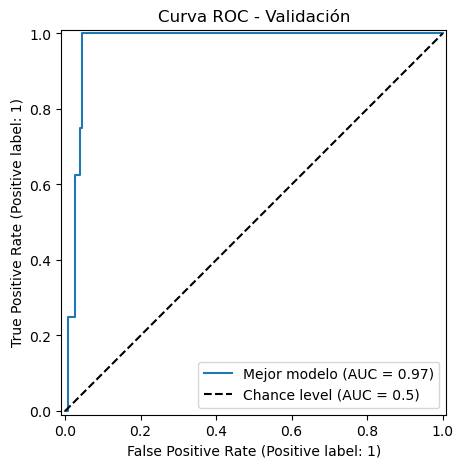

In [15]:
# Respuesta Ejercicio-6c:

# **+++++++++++ Inicia sección para agregar código ++++++++++++++**

fig, ax = plt.subplots(figsize=(6, 5))
RocCurveDisplay.from_estimator(mejor_modelo, Xval, np.ravel(yval), name='Mejor modelo',
                               plot_chance_level=True, ax=ax)
ax.set_title('Curva ROC - Validación')
plt.show()

# **+++++++++++ Termina sección para agregar código ++++++++++++++**

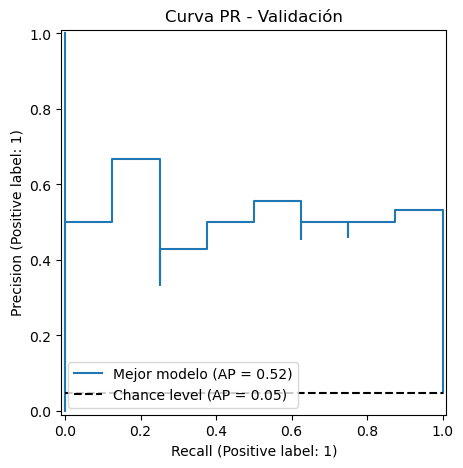

In [16]:
# Respuesta Ejercicio 6d:

# **+++++++++++ Inicia sección para agregar código ++++++++++++++**

fig, ax = plt.subplots(figsize=(6, 5))
PrecisionRecallDisplay.from_estimator(mejor_modelo, Xval, np.ravel(yval), name='Mejor modelo',
                                      plot_chance_level=True, ax=ax)
ax.set_title('Curva PR - Validación')
plt.show()

# **+++++++++++ Termina sección para agregar código ++++++++++++++**

Respuesta Ejercicio-6e:

### +++++++++++ Inicia sección para agregar texto ++++++++++++++++

**6e)** En la curva ROC, el AUC del modelo es 0.973, muy por encima del 0.5 del azar. El modelo ordena casi perfectamente las imágenes: casi siempre asigna más probabilidad de derrame a una imagen con derrame que a una limpia. Sin embargo, como vimos durante el curso, con clases tan desbalanceadas la curva ROC es optimista. La tasa de falsos positivos se divide entre 157 negativos, así que 12 falsas alarmas representan solo un 7.6%.

La curva PR es más informativa para este tipo de problemas. Su precisión promedio (AP) es 0.523, unas 11 veces la del modelo al azar (0.048), pero la precisión cae cuando exigimos detectar todos los derrames: con el umbral de 0.5, 12 de las 20 alertas (60%) son falsas alarmas.

Operativamente, el modelo sirve como filtro de detección. Además, con solo 8 positivos en validación, ambas curvas tienen alta incertidumbre ya que cada dato tiene un peso de 12.5% del recall.

### +++++++++++ Termina sección para agregar texto ++++++++++++++

In [17]:
# Mostremos finalmente el siguiente resumen con varias métricas:

print(classification_report_imbalanced(np.ravel(yval), yval_hat,
                                       target_names=['class 0:non-spill', 'class 1:oil-spill']))



                         pre       rec       spe        f1       geo       iba       sup

class 0:non-spill       1.00      0.92      1.00      0.96      0.96      0.92       157
class 1:oil-spill       0.40      1.00      0.92      0.57      0.96      0.93         8

      avg / total       0.97      0.93      1.00      0.94      0.96      0.92       165



# **Ejercicio-7**

En los ejercicios previos ya lograste entrenar un buen modelo utilizando la métrica G-mean. Sin embargo, sabemos que en la industria un modelo no se despliega solamente porque tiene buenas métricas estadísticas, se despliega para resolver un problema de negocio. Introduzcamos a continuación información en esta dirección.

En los ejercicios anteriores el umbral de decisión por defecto del modelo logístico (independientemente de si usamos L1, L2 o ElasticNet) fue 0.5. Con este valor de decisión de 0.5 y del reporte de métricas de la celda anterior, observamos que aproximadamente el modelo detecta el 100% de los derrames (Recall ≈ 1.0), pero a costa de generar muchas falsas alarmas (Precisión ≈ 0.32).

Sabemos que el umbral de decisión predeterminado de 0.5 de los modelos logísticos es una convención arbitraria. Como ingenieros de IA, deberán ajustar ahora este umbral tomando en cuenta el costo de de cada nuno de los errores.

* **El Escenario de Negocio es el siguiente: Imagina que estás desplegando este modelo para la Guardia Costera y la Agencia de Protección Ambiental y te proporcionan la siguiente información:**

   * **Costo de un Falso Negativo (FN):** Cuando el modelo predice erróneamente que el "océano está limpio" y que no hay derrame de combustible, el costo es de $1,000,000 USD. El costo considera multas, limpieza de emergencia, daño ecológico, técnicos especialistas, disminución de tu reputación, etc.

   * **Costo de un Falso Positivo (FP):** Cuando el modelo predice erróneamente que "sí hay derrame", el costo es de $15,000 USD. Puede ser la detección de los llamados casos "look-alike", como las manchas de algas, entre otros. El costo considera el uso y combustible de un helicóptero para inspeccionar, horas hombre, entre otros.

   * El costo de error de los **casos Verdaderos (TP y TN)** es de $0 USD.

* **7a) Con base a esta información y tu mejor modelo encontrado previamente, utiliza un modelo de lenguaje de gran tamaño, LLM, para que te ayude a escribir una función en Python que calcule el "Costo Total Esperado" del problema, iterando a través de diferentes umbrales de probabilidad (desde 0.1 hasta 0.9). Utiliza solamente el conjunto de validación.**

* **7b) Incluye además una gráfica del Costo Total Esperado (eje Y)contre el valor de umbral (eje X). Despliega e indica visualmente dicho valor del umbral óptimo obtenido y su valor del costo total asociado.**

* **7c) A modo de comparación, muestra la matriz de confusión (en valores brutos) y el valor de la métrica G-mean para el caso del umbral de decisión predeterminado 0.5 y el del mejor umbral obtenido en los incisos anteriores.**

* **7d) ¿Cómo cambia la estrategia de despliegue respecto al umbral original predeterminado de 0.5? En particular, ¿consideras que vale la pena cambiarlo?**

* **7e) Indica el LLM utilizado e incluye el prompt o prompts que usaste en los incisos 7a y 7b anteriores.**





Umbral óptimo = 0.73  | Costo = $105,000  (vs $180,000 con umbral 0.5)


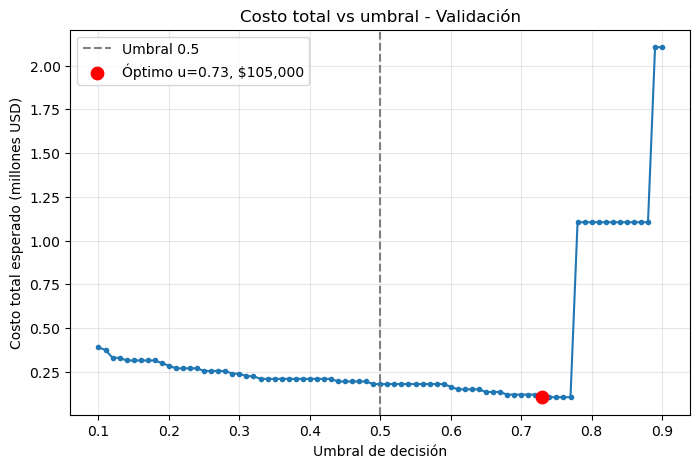


Umbral 0.50  G-mean = 0.9610
[[145  12]
 [  0   8]]

Umbral 0.73  G-mean = 0.9775
[[150   7]
 [  0   8]]


In [18]:
# Respuesta Ejercicio 7:

# +++++++ Incluye a continuación todos las celdas de texto y código que consideres adecuadas.

COSTO_FN, COSTO_FP = 1_000_000, 15_000

def costo_total_esperado(y_true, y_proba, umbrales=np.round(np.arange(0.10, 0.91, 0.01), 2)):
    """Calcula FP, FN y el costo total para cada umbral de decisión."""
    filas = []
    for u in umbrales:
        y_pred = (y_proba >= u).astype(int)
        tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
        filas.append({'umbral': u, 'TN': tn, 'FP': fp, 'FN': fn, 'TP': tp,
                      'costo': fn * COSTO_FN + fp * COSTO_FP})
    return pd.DataFrame(filas)

yval_proba = mejor_modelo.predict_proba(Xval)[:, 1]
tabla_costos = costo_total_esperado(np.ravel(yval), yval_proba)

i_opt = tabla_costos['costo'].idxmin()          # si hay empate, toma el umbral más bajo (más conservador)
u_opt, c_opt = tabla_costos.loc[i_opt, ['umbral', 'costo']]
c_05 = tabla_costos.loc[tabla_costos['umbral'] == 0.5, 'costo'].iloc[0]
print(f'Umbral óptimo = {u_opt:.2f}  | Costo = ${c_opt:,.0f}  (vs ${c_05:,.0f} con umbral 0.5)')

plt.figure(figsize=(8, 5))
plt.plot(tabla_costos['umbral'], tabla_costos['costo'] / 1e6, marker='.')
plt.axvline(0.5, ls='--', c='gray', label='Umbral 0.5')
plt.scatter([u_opt], [c_opt / 1e6], c='red', s=80, zorder=3,
            label=f'Óptimo u={u_opt:.2f}, ${c_opt:,.0f}')
plt.xlabel('Umbral de decisión')
plt.ylabel('Costo total esperado (millones USD)')
plt.title('Costo total vs umbral - Validación')
plt.legend()
plt.grid(alpha=.3)
plt.show()


for u in [0.5, u_opt]:
    yp = (yval_proba >= u).astype(int)
    print(f'\nUmbral {u:.2f}  G-mean = {geometric_mean_score(np.ravel(yval), yp):.4f}')
    print(confusion_matrix(np.ravel(yval), yp))


**7d)** Un falso negativo cuesta lo mismo que unos 67 falsos positivos ($1,000,000 vs $15,000 USD), así que el costo está dominado por no perder ningún derrame. Con el umbral de 0.5, el modelo detecta los 8 derrames con 12 falsas alarmas: costo de $180,000. Con el umbral óptimo de 0.73 sigue detectando los 8 pero las falsas alarmas bajan a 7: costo de $105,000 (42% menos). Por su parte, el G-mean sube de 0.961 a 0.978.

Sin embargo, el derrame con menor probabilidad asignada tiene 0.771. Un umbral de 0.80 ya pierde un derrame y el costo salta a $1,105,000. Entonces, podríamos decir que el óptimo está a muy poca distancia de ese borde. Bajar el costo $75,000 arriesga perder $1,000,000.

Una recomendación sería no subir el umbral hasta 0.73. Conviene mantener un valor intermedio con margen de seguridad (e.g. 0.65), y validar el umbral con más datos o con validación cruzada antes de cambiarlo. **El modelo no se despliega para minimizar falsas alarmas, sino para no dejar pasar derrames**.

**7e)** LLM utilizado: Claude (Anthropic), modelo Claude Opus 5.5, vía Claude Code. Prompt:

<blockquote style="font-style: italic;">

Sea mejor_modelo un modelo de clasificación binaria en scikit-learn (Pipeline con LogisticRegression) para detectar derrames de petróleo, y un conjunto de validación Xval, yval. Si tenemos que:
* Un falso negativo cuesta 1,000,000 USD
* Un falso positivo cuesta 15,000 USD
* Los aciertos cuestan 0 USD. 

Escribe una función en Python que, usando predict_proba y umbrales de 0.1 a 0.9 (con salto de 0.01), calcule el costo total esperado junto con la matriz de confusión. Devuelve un DataFrame con los resultados y encuentra el umbral de menor costo. Después grafica costo total (eje Y) vs umbral (eje X), marcando el umbral óptimo y su costo. Usa el umbral 0.5 como referencia.

</blockquote>

# **Ejercicio-8**

**Has completado el ciclo de desarrollo y análisis del modelo de detección de derrames. Considera que tenemos el problema de derramamiento de combustible anterior y todo el análisis que has realizado hasta ahora. A continuación, deberás hacer un reporte para "vender tu solución". Para ello, considera el siguiente escenario:**

* **Supongamos que eres el ingeniero líder de IA de la Guarda Costera. A tu Director de Operaciones (que no conoce de tecnicismos de IA o Estadística) le hicieron llegar un reporte generado automáticamente por una herramienta de Inteligencia de Negocio (BI, por sus siglas en inglés). La conclusión de dicho reporte dice lo siguiente:**

     * **"El modelo tiene una Exactitud (Accuracy) del 96%. ¡Es casi perfecto! Propongo despedir a los 3 analistas humanos y dejar que el modelo envíe automáticamente los helicópteros de inspección cada vez que detecte algo".**


* **Tú sabes que esta conclusión es peligrosa e incorrecta tan solo por el alto desbalanceo de clases, pero además porque ya tienes los resultados analíticos anteriores de esta actividad que te pueden ayudar a soportar mejores decisiones y refutar la conlusión del reporte de la herramienta de BI.**

* **Redacta un reporte ejecutivo de máximo 1 página (400 palabras aproximadamente) dirigido al Director de Operaciones y con las siguientes características:**
   * **El reporte no debe estar lleno te fórmulas o métricas. En dado caso, si decides mencionar explícitamente por ejemplo "G-mean" o "curva ROC", deberás primero explicarlas.**
   
   * **El reporte debe incluir una explicación de las implicaciones de cometer errores de FP o FN con el modelo ingenuo, en comparación con los resultados de tu mejor modelo. La explicación debe ser nuevamente en el contexto del problema y sin tecnicismos.**

   * **Propón un plan de despliegue concreto del modelo que justifique y ayude a mantener a los 2 analistas humanos en sus puestos de trabajo. NOTA: Puedes revisar y aporate en el concepto conocido en inglés como "Human-in-the-loop" en IA.**







Respuesta Ejercicio-8):

### +++++++++++ Inicia sección para agregar texto ++++++++++++++++

Estimado Director de Operaciones:

Revisando el reporte automático, se afirma que es “casi perfecto” porque acierta en el 96% de los casos. Sin embargo, dicha cifra es engañosa. Menos de 5 imágenes de cada 100 contienen un derrame. Incluso un sistema que siempre responda “el mar está limpio” sin analizar nada, también acertará el 96% de las veces sin detectar ni un solo derrame. El 96% está midiendo lo fácil (reconocer agua limpia), no lo verdaderamente importante (encontrar petróleo).

¿Cuánto cuestan los errores? Dividamos estos en dos:
* **Falsa alarma**: se envía un helicóptero y no hay derrame (aprox. $15,000).
* **Derrame no detectado**: el petróleo se extiende sin respuesta. Provoca multas, limpieza de emergencia, daño ecológico y reputacional (aprox. $1,000,000).

En 165 imágenes con 8 derrames reales (seleccionadas para evaluar los modelos): El sistema “ingenuo” del 96% de exactitud habría dejado pasar los 8 derrames: un costo de aproximadamente **$8 millones en pérdidas**. Sin embargo, ajustando nuestro propio modelo, logramos detectar los 8 derrames a cambio de unas 12 falsas alarmas: un costo de **$180,000**.

**Es una reducción del 97% en el costo de los errores**. Por eso evaluamos el modelo con una medida que exige acertar en ambas situaciones a la vez (cuando hay y cuando no hay derrame en cada imagen), y no solo con el porcentaje general de aciertos.

Aunque hay una mejora en la detección de casos reales, se debe considerar que aproximadamente 3 de cada 5 alertas del modelo son **falsas alarmas**: manchas de algas o zonas de mar en calma que en la imagen “se parecen” al petróleo. Si el modelo mandara helicópteros automáticamente, pagaríamos todas esas falsas alarmas y el personal de vuelo dejaría de confiar en el sistema.

**Propuesta de despliegue**:
* Filtro automático: el modelo revisa el 100% de las imágenes y descarta las claramente limpias. Así el equipo solo examina una fracción del total.
* Validación humana: los 2 analistas revisan cada alerta y deciden si enviar el helicóptero. Su experiencia elimina gran parte de las falsas alarmas.
* Auditoría: los analistas revisan una muestra de las imágenes que el modelo marcó como limpias, para detectar derrames omitidos.
* Mejora continua: cada decisión de los analistas se registra y se usa para reentrenar el modelo.

Así, **el modelo trabaja como asistente del equipo de analistas, no como su reemplazo**. Aporta velocidad y cobertura; los 2 analistas aportan criterio y control de calidad. Juntos minimizan el riesgo de un derrame no detectado, que es el error que puede costarnos millones.

### +++++++++++ Termina sección para agregar texto ++++++++++++++

# **Ejercicio-9**

### **Incluye tus conclusiones finales.**


### +++++++++++ Inicia sección de Conclusiones ++++++++++++++++

* Con clases muy desbalanceadas (e.g. 4% de positivos), la exactitud es una métrica engañosa: incluso el modelo trivial supera fácilmente el 96% sin detectar ningún derrame. En este contexto, G-mean obliga a desempeñarse bien en ambas clases y permite distinguir modelos útiles de modelos ingenuos.

* Establecer un baseline con DummyClassifier resulta útil para detectar subentrenamiento: un número “alto” no significa nada sin una referencia.

* Los modelos con valores predeterminados no resuelven el problema. El ajuste que más impacto tuvo fue `class_weight='balanced'`, que mejoró significativamente la G-mean en la validación cruzada (pasó de 0.50-0.65 a 0.75-0.85). Después, al exigir una brecha entre entrenamiento y validación menor al 3%, el mejor modelo fue LASSO con C = 10. Con esto logramos detectar los 8 derrames de validación con 12 falsas alarmas.

* Las curvas ROC y PR son complementarias. La ROC muestra buena capacidad de ordenamiento, pero la PR revela el costo real en falsas alarmas cuando se busca recall alto.
* El umbral de 0.5 es por convención. Al incorporar los costos del negocio, el umbral óptimo se puede ajustar tomando como criterio de decisión el costo total.
* Desde el punto de vista ético y operativo, el modelo debe complementar el juicio humano (“human-in-the-loop”) y no reemplazarlo.

### +++++++++++ Termina sección de conclusiones ++++++++++++++

# **<<< Fin de la Actividad de la Semana - Clases Desbalanceadas - Oil-Spill >>>**